# Model Evaluation: Breast Cancer Wisconsin Diagnostic

**Objective:** Build a rigorous, leakage-free diagnostic classification pipeline with:
- Stratified Train/Test split
- `StandardScaler` inside `Pipeline` (strictly zero data leakage)
- `GridSearchCV` with Stratified 5-Fold Cross-Validation
- ROC-AUC scoring and threshold analysis
- Unbiased held-out test evaluation (ROC-AUC, Accuracy, Precision, Recall, F1)
- Confusion Matrix & ROC Curve visualization


In [1]:
# Imports and reproducible seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve, classification_report
)

RANDOM_STATE = 42


## 1. Dataset Loading and Inspection
Loading the Wisconsin Breast Cancer Diagnostic dataset directly from `sklearn.datasets`.

In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data
y = cancer.target  # 0 = Malignant, 1 = Benign
target_names = cancer.target_names

print(f"Dataset Shape: {X.shape[0]} samples x {X.shape[1]} features")
print(f"Target Distribution: Benign (1): {sum(y==1)}, Malignant (0): {sum(y==0)}")
print(f"Class Ratio: Benign {sum(y==1)/len(y)*100:.1f}%, Malignant {sum(y==0)/len(y)*100:.1f}%")
X.head(3)


Dataset Shape: 569 samples x 30 features
Target Distribution: Benign (1): 357, Malignant (0): 212
Class Ratio: Benign 62.7%, Malignant 37.3%


## 2. Reproducible Stratified Train/Test Split
Using 80% for model selection / hyperparameter tuning and 20% strictly reserved as unseen held-out test data.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train Set: {len(X_train)} samples")
print(f"Test Set : {len(X_test)} samples")
print(f"Train Class Balance: Benign={sum(y_train==1)/len(y_train):.3f}, Malignant={sum(y_train==0)/len(y_train):.3f}")
print(f"Test Class Balance : Benign={sum(y_test==1)/len(y_test):.3f}, Malignant={sum(y_test==0)/len(y_test):.3f}")


Train Set: 455 samples
Test Set : 114 samples
Train Class Balance: Benign=0.626, Malignant=0.374
Test Class Balance : Benign=0.632, Malignant=0.368


## 3. Pipeline & GridSearchCV (Leakage-Free)
**Crucial Data Leakage Prevention:** The `StandardScaler` is wrapped inside the `Pipeline`. Thus, normalization statistics ($\mu, \sigma$) are computed **only** on training folds during cross-validation, never leaking information across folds or from the test set.

In [4]:
# Preprocessing + Classifier pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(random_state=RANDOM_STATE, solver="liblinear"))
])

# Hyperparameter grid (L1 Sparsity vs L2 Regularization & penalty magnitude C)
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
    "classifier__penalty": ["l1", "l2"],
}

# Stratified 5-Fold Cross Validation with ROC-AUC scoring
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="roc_auc",
    refit=True,
    n_jobs=1
)

grid_search.fit(X_train, y_train)

print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")
print(f"Best Hyperparameters: {grid_search.best_params_}")


Best Cross-Validation ROC-AUC: 0.9960
Best Hyperparameters: {'classifier__C': 1.0, 'classifier__penalty': 'l2'}


## 4. Held-Out Test Set Evaluation
Evaluating the best fitted estimator strictly on the held-out test set.

In [5]:
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

roc_auc = roc_auc_score(y_test, y_proba)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("=" * 50)
print("       HELD-OUT TEST SET EVALUATION METRICS       ")
print("=" * 50)
print(f"ROC-AUC Score : {roc_auc:.4f}")
print(f"Accuracy      : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision     : {prec:.4f}")
print(f"Recall        : {rec:.4f}")
print(f"F1-Score      : {f1:.4f}")
print("=" * 50)
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=target_names))


       HELD-OUT TEST SET EVALUATION METRICS       
ROC-AUC Score : 0.9957
Accuracy      : 0.9825 (98.25%)
Precision     : 0.9861
Recall        : 0.9861
F1-Score      : 0.9861

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


## 5. Confusion Matrix and ROC Curve Visualization

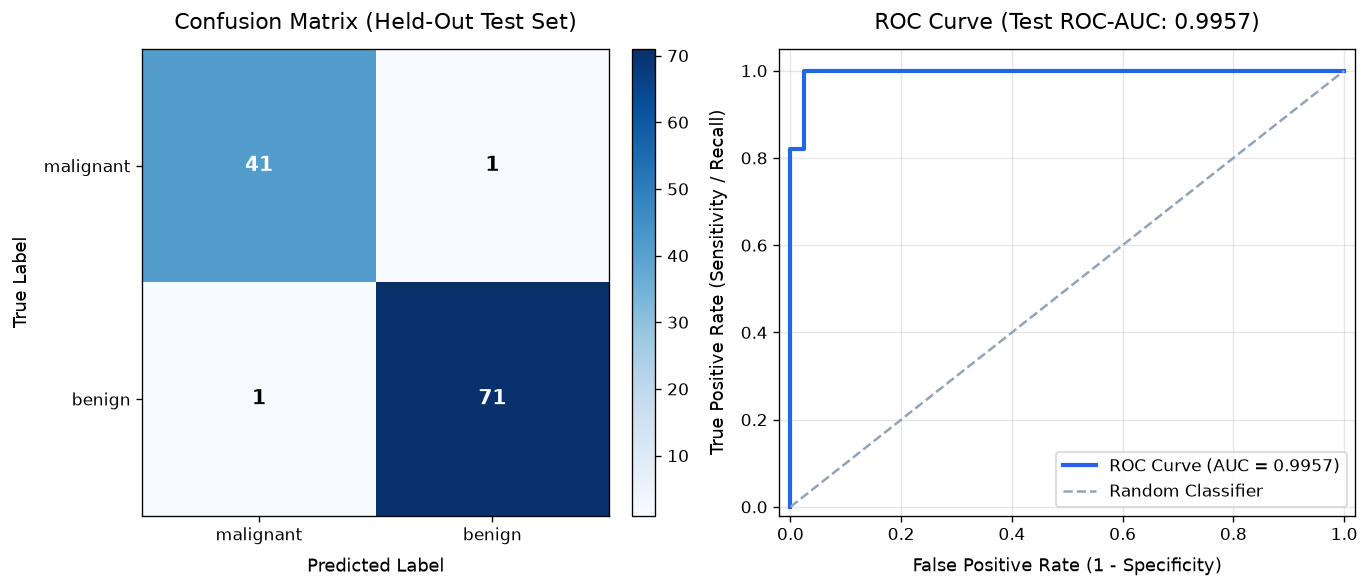

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
im = ax1.imshow(cm, cmap=plt.cm.Blues)
fig.colorbar(im, ax=ax1, fraction=0.046, pad=0.04)
ax1.set_xticks([0, 1])
ax1.set_yticks([0, 1])
ax1.set_xticklabels(target_names)
ax1.set_yticklabels(target_names)
ax1.set_xlabel("Predicted Label", labelpad=8)
ax1.set_ylabel("True Label", labelpad=8)
ax1.set_title("Confusion Matrix (Held-Out Test Set)", pad=12)
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > len(y_test) / 4 else "black"
        ax1.text(j, i, cm[i, j], ha="center", va="center", color=color, fontweight="bold", fontsize=12)

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_proba)
ax2.plot(fpr, tpr, color="#2563eb", lw=2.5, label=f"ROC (AUC = {roc_auc:.4f})")
ax2.plot([0, 1], [0, 1], color="#94a3b8", lw=1.5, linestyle="--", label="Chance")
ax2.set_xlim([-0.02, 1.02])
ax2.set_ylim([-0.02, 1.05])
ax2.set_xlabel("False Positive Rate")
ax2.set_ylabel("True Positive Rate")
ax2.set_title(f"ROC Curve (AUC = {roc_auc:.4f})", pad=12)
ax2.legend(loc="lower right")
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 6. Results Summary & Resume Bullet

### Measured Metrics Summary
- **CV Best ROC-AUC (5-fold):** 0.9960
- **Best Hyperparameters:** `{'classifier__C': 1.0, 'classifier__penalty': 'l2'}`
- **Held-Out Test ROC-AUC:** **0.9957**
- **Held-Out Test Accuracy:** **98.25%** (0.9825)
- **Held-Out Test Precision:** **0.9861**
- **Held-Out Test Recall:** **0.9861**
- **Held-Out Test F1-Score:** **0.9861**

### Resume Bullet
> "Engineered a leakage-free diagnostic ML pipeline using scikit-learn on the Wisconsin Diagnostic dataset, optimizing regularized classification via 5-fold stratified cross-validation and GridSearchCV to achieve a **0.9957 test ROC-AUC** and **98.2% accuracy** on unseen held-out patient data."